# Modeling Human Activity States Using Hidden Markov Models

**Formative 2: Human Activity Recognition (HAR) with a from-scratch HMM**

Use case: a phone or wearable monitor for older adults living alone. It infers the wearer's activity
(*standing, walking, jumping, still*). It flags long periods of inactivity, and it flags sudden violent
movement that could be a fall or a seizure.

Pipeline:
1. **Data**: load the Sensor Logger exports (accelerometer and gyroscope), check and harmonise the sampling rate, trim, merge, clean.
2. **Features**: 2 s windows with 50 % overlap, time- and frequency-domain features, Z-score normalisation (fit on train only).
3. **HMM**: Gaussian-emission HMM written from scratch in numpy (forward/backward in log space, Viterbi, multi-sequence Baum-Welch).
4. **Evaluation**: unseen test recordings, with sensitivity, specificity, accuracy, a confusion matrix and decoded sequences.

Every number in the report comes from this notebook. Run it top to bottom (`Kernel → Restart & Run All`).

In [1]:
from __future__ import annotations

import json
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment

SEED = 42
rng = np.random.default_rng(SEED)

# --- paths -----------------------------------------------------------------
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_TRAIN = ROOT / "data" / "raw" / "train"
RAW_TEST = ROOT / "data" / "raw" / "test"
LABELS_DIR = ROOT / "data" / "labels"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "figures"
for p in (PROC / "train", PROC / "test", FIG):
    p.mkdir(parents=True, exist_ok=True)

# --- global constants ------------------------------------------------------
ACTIVITIES = ["standing", "walking", "jumping", "still"]   # hidden states, fixed order
FS = 50.0            # common (target) sampling rate in Hz
TRIM_S = 2.0         # seconds trimmed from each end (start/stop button taps)
WIN_S = 2.0          # window length in seconds
OVERLAP = 0.5        # fractional window overlap
WIN = int(WIN_S * FS)            # samples per window, derived from FS
STEP = int(WIN * (1 - OVERLAP))  # hop size in samples

PALETTE = dict(zip(ACTIVITIES, ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]))
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

def savefig(fig: plt.Figure, name: str) -> None:
    # Save a figure as PNG in figures/ (it is also shown inline).
    fig.savefig(FIG / f"{name}.png")

RESULTS: dict = {}   # every number the report uses gets collected here and dumped to JSON
print(f"FS={FS} Hz, window={WIN} samples ({WIN_S}s), step={STEP} samples, FFT resolution={FS/WIN:.2f} Hz")

FS=50.0 Hz, window=100 samples (2.0s), step=50 samples, FFT resolution=0.50 Hz


## 1. Data Collection and Pre-processing

Each recording is an unzipped **Sensor Logger (iOS)** export: one folder per recording, named
`<label>_<NN>-<timestamp>`. We use `Accelerometer.csv` (iOS *user acceleration*, gravity removed, in m/s²)
and `Gyroscope.csv` (rad/s). Columns come in the order `time, seconds_elapsed, z, y, x`, so we always select them **by name**.
The two sensors share timestamps, so we merge them with an inner join on `time`.

Raw files are never modified. All cleaning happens here, and the cleaned outputs go to `data/processed/`.

In [2]:
def parse_label(folder: Path) -> str:
    """Activity label = part of the folder name before the first '_'."""
    return folder.name.split("_")[0]


def read_metadata(folder: Path) -> dict:
    """Read device name and the configured sample period from Metadata.csv."""
    meta = pd.read_csv(folder / "Metadata.csv").iloc[0]
    periods = [float(p) for p in str(meta["sampleRateMs"]).split("|") if p not in ("", "nan")]
    return {"device": meta["device name"], "configured_ms": periods[0] if periods else np.nan}


def load_recording(folder: Path) -> pd.DataFrame:
    """Load one Sensor Logger recording and merge accelerometer + gyroscope on `time`.

    Returns a DataFrame with columns t (s, starting at 0), acc_x/y/z (m/s^2), gyro_x/y/z (rad/s).
    """
    acc = pd.read_csv(folder / "Accelerometer.csv")[["time", "x", "y", "z"]]
    gyr = pd.read_csv(folder / "Gyroscope.csv")[["time", "x", "y", "z"]]
    acc = acc.rename(columns={c: f"acc_{c}" for c in "xyz"})
    gyr = gyr.rename(columns={c: f"gyro_{c}" for c in "xyz"})
    df = acc.merge(gyr, on="time", how="inner").sort_values("time").drop_duplicates("time")
    df.insert(0, "t", (df["time"] - df["time"].iloc[0]) / 1e9)
    return df.drop(columns="time").reset_index(drop=True)


def detect_rate(t: np.ndarray) -> float:
    """Sampling rate (Hz) estimated from the median timestamp difference."""
    return float(1.0 / np.median(np.diff(t)))

In [3]:
def inventory(raw_dir: Path) -> pd.DataFrame:
    """List every recording folder with label, device, configured and detected rate, and duration."""
    rows = []
    for folder in sorted(p for p in raw_dir.iterdir() if p.is_dir()):
        df = load_recording(folder)
        meta = read_metadata(folder)
        rows.append({
            "recording": folder.name.split("-")[0],
            "folder": folder.name,
            "label": parse_label(folder),
            "device": meta["device"],
            "configured_hz": 1000.0 / meta["configured_ms"],
            "detected_hz": detect_rate(df["t"].to_numpy()),
            "n_samples": len(df),
            "raw_duration_s": df["t"].iloc[-1],
        })
    return pd.DataFrame(rows)

train_inv = inventory(RAW_TRAIN)
unexpected = train_inv.loc[~train_inv["label"].isin(ACTIVITIES), "folder"].tolist()
assert not unexpected, f"Folders with unexpected labels: {unexpected}"
print("All training folder labels are valid:", sorted(train_inv["label"].unique()))
train_inv.head()

All training folder labels are valid: ['jumping', 'standing', 'still', 'walking']


,recording,folder,label,device,configured_hz,detected_hz,n_samples,raw_duration_s
0,jumping_01,jumping_01-2026-10-30_10-09-52,jumping,iPhone XS,50.0,49.769072,674,13.522277
1,jumping_02,jumping_02-2026-10-30_10-10-09,jumping,iPhone XS,50.0,49.770558,824,16.536120
2,jumping_03,jumping_03-2026-10-30_10-10-33,jumping,iPhone XS,50.0,49.770558,659,13.220806
3,jumping_04,jumping_04-2026-10-30_10-10-48,jumping,iPhone XS,50.0,49.769072,631,12.658296
4,jumping_05,jumping_05-2026-10-30_10-11-41,jumping,iPhone XS,50.0,49.766099,665,13.342264


### 1.1 Sampling-rate check and harmonisation

The brief asks us to harmonise sampling rates across phones. We do not trust the configured value alone.
We **detect** each file's rate from its timestamps (the median Δt), compare it to `sampleRateMs` in `Metadata.csv`,
and then resample *every* recording onto a uniform 50 Hz grid with linear interpolation.
This step is needed when phones differ (for example a 100 Hz Android phone and a 50 Hz iPhone).
It also removes small timestamp jitter, so that a 100-sample window is always exactly 2.0 s
and FFT bins sit at the same frequencies for every file.

,files,configured_hz,detected_hz_mean,detected_hz_min,detected_hz_max
device,,,,,
iPhone XS,48,50.0,49.77,49.76,49.77


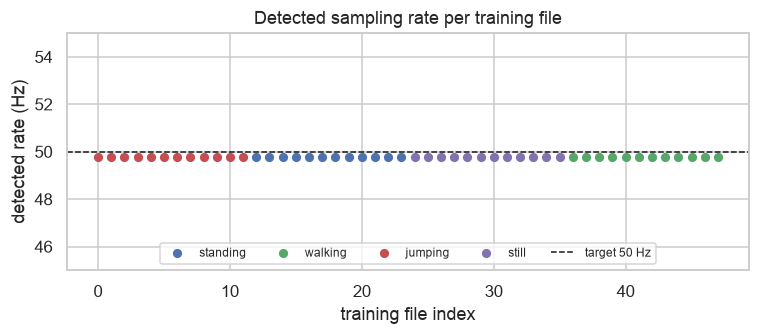

In [4]:
rate_summary = (train_inv.groupby("device")
                .agg(files=("folder", "count"), configured_hz=("configured_hz", "mean"),
                     detected_hz_mean=("detected_hz", "mean"), detected_hz_min=("detected_hz", "min"),
                     detected_hz_max=("detected_hz", "max"))
                .round(2))
display(rate_summary)

RESULTS["devices"] = rate_summary.reset_index().to_dict(orient="records")
RESULTS["detected_hz_range"] = [round(train_inv.detected_hz.min(), 2), round(train_inv.detected_hz.max(), 2)]

fig, ax = plt.subplots(figsize=(8, 2.8))
for lab in ACTIVITIES:
    sub = train_inv[train_inv.label == lab]
    ax.scatter(sub.index, sub.detected_hz, label=lab, color=PALETTE[lab], s=25)
ax.axhline(FS, ls="--", c="k", lw=1, label=f"target {FS:.0f} Hz")
ax.set(xlabel="training file index", ylabel="detected rate (Hz)", title="Detected sampling rate per training file",
       ylim=(FS - 5, FS + 5))
ax.legend(ncol=5, fontsize=8, loc="lower center")
savefig(fig, "fig_sampling_rates"); plt.show()

In [5]:
def resample(df: pd.DataFrame, fs: float = FS) -> pd.DataFrame:
    """Resample all signal columns onto a uniform grid at `fs` Hz with linear interpolation.

    Harmonises phones with different (or jittery) sampling rates. Grid: 0, 1/fs, ..., <= last timestamp.
    """
    t = df["t"].to_numpy()
    grid = np.arange(0.0, t[-1], 1.0 / fs)
    out = {"t": grid}
    for col in df.columns.drop("t"):
        out[col] = np.interp(grid, t, df[col].to_numpy())
    return pd.DataFrame(out)


def trim(df: pd.DataFrame, seconds: float = TRIM_S) -> pd.DataFrame:
    """Drop the first and last `seconds` (phone taps at start/stop), then re-zero time."""
    out = df[(df["t"] >= seconds) & (df["t"] <= df["t"].iloc[-1] - seconds)].copy()
    out["t"] -= out["t"].iloc[0]
    return out.reset_index(drop=True)


def clean_recording(folder: Path) -> pd.DataFrame:
    """Full cleaning chain: load+merge -> drop NaNs -> resample to FS -> trim lead-in/out."""
    df = load_recording(folder).dropna()
    return trim(resample(df, FS), TRIM_S)

In [6]:
SIGNALS = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]

train_recs: dict[str, pd.DataFrame] = {}
for _, row in train_inv.iterrows():
    df = clean_recording(RAW_TRAIN / row.folder)
    df.insert(1, "label", row.label)
    train_recs[row.recording] = df
    df.to_csv(PROC / "train" / f"{row.recording}.csv", index=False)

train_inv["clean_duration_s"] = [train_recs[r]["t"].iloc[-1] + 1 / FS for r in train_inv.recording]
n_nan = sum(int(df[SIGNALS].isna().sum().sum()) for df in train_recs.values())
print(f"Cleaned {len(train_recs)} recordings -> data/processed/train/  (NaNs remaining: {n_nan})")

summary = (train_inv.groupby("label")
           .agg(files=("folder", "count"), raw_seconds=("raw_duration_s", "sum"),
                clean_seconds=("clean_duration_s", "sum"), mean_clean_s=("clean_duration_s", "mean"))
           .reindex(ACTIVITIES).round(1))
summary.loc["TOTAL"] = [summary.files.sum(), summary.raw_seconds.sum(), summary.clean_seconds.sum(),
                        train_inv.clean_duration_s.mean().round(1)]
display(summary)

MIN_S = 90.0
for lab in ACTIVITIES:
    s = summary.loc[lab, "clean_seconds"]
    status = "OK" if s >= MIN_S else f"SHORT by {MIN_S - s:.1f} s -> record more"
    print(f"{lab:9s}: {s:6.1f} s of clean data (>= {MIN_S:.0f} s required) -> {status}")

RESULTS["train_summary"] = summary.reset_index().rename(columns={"index": "label"}).to_dict(orient="records")
RESULTS["n_train_files"] = int(len(train_inv))
RESULTS["clean_duration_range"] = [round(train_inv.clean_duration_s.min(), 2), round(train_inv.clean_duration_s.max(), 2)]

Cleaned 48 recordings -> data/processed/train/  (NaNs remaining: 0)


,files,raw_seconds,clean_seconds,mean_clean_s
label,,,,
standing,12,165.6,117.8,9.8
walking,12,163.7,115.9,9.7
jumping,12,163.4,115.6,9.6
still,12,162.2,114.4,9.5
TOTAL,48,654.9,463.7,9.7


standing :  117.8 s of clean data (>= 90 s required) -> OK
walking  :  115.9 s of clean data (>= 90 s required) -> OK
jumping  :  115.6 s of clean data (>= 90 s required) -> OK
still    :  114.4 s of clean data (>= 90 s required) -> OK


### 1.2 Raw signal visualisation

One cleaned recording per activity. The scales differ a lot: *still* (phone on a table) is almost flat
(only sensor noise), while *jumping* produces large spikes (around ±40 m/s²) at the landing of each jump.

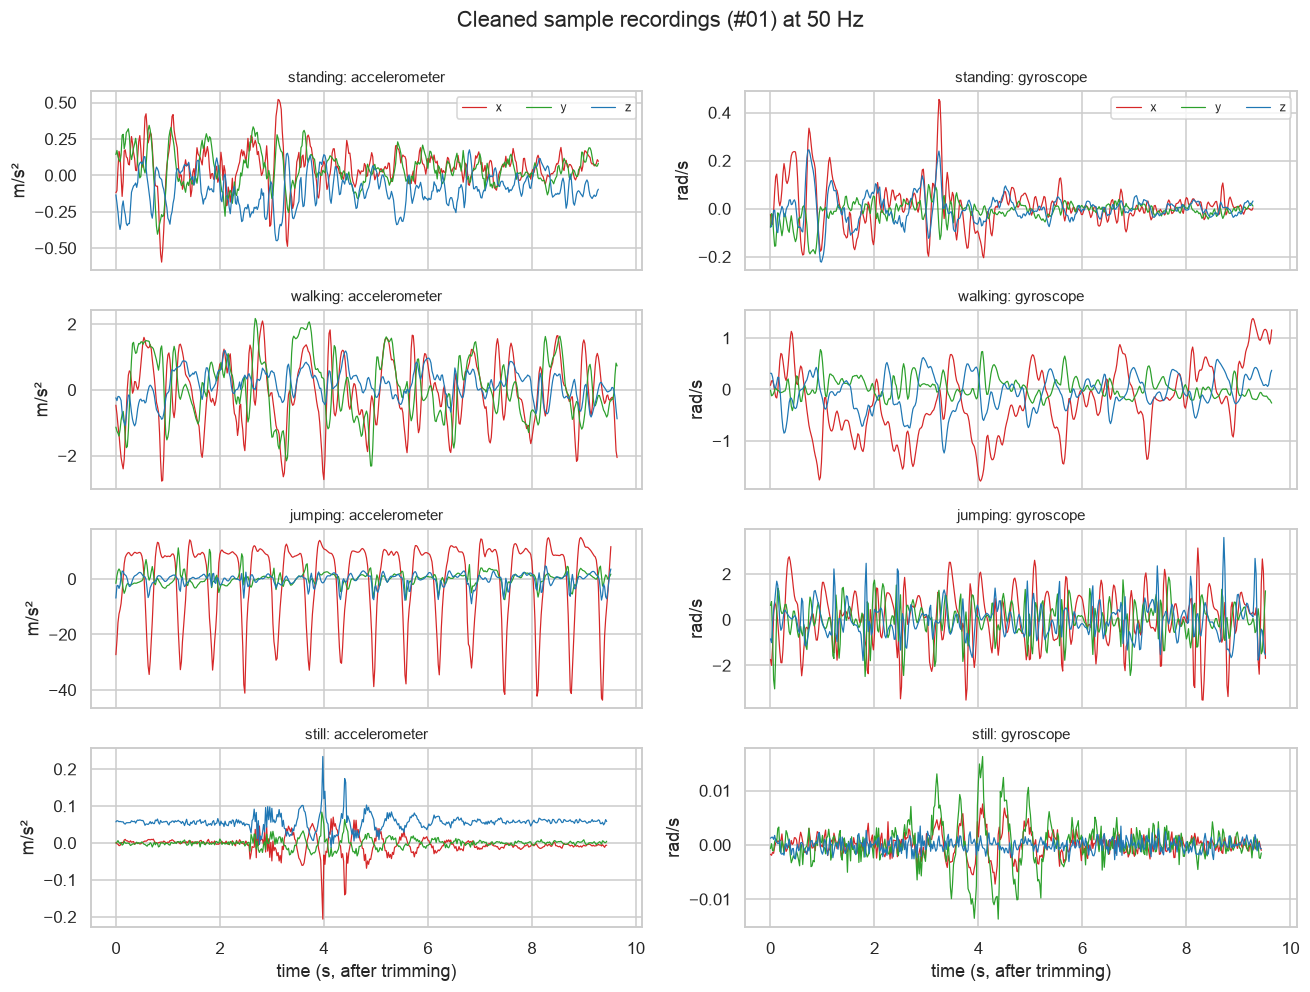

In [7]:
def plot_raw_examples(recs: dict[str, pd.DataFrame], idx: str = "01") -> plt.Figure:
    """Grid of acc / gyro x-y-z traces, one row per activity."""
    fig, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(12, 9), sharex=True)
    for i, lab in enumerate(ACTIVITIES):
        df = recs[f"{lab}_{idx}"]
        for j, sensor in enumerate(["acc", "gyro"]):
            ax = axes[i, j]
            for axis, c in zip("xyz", ["tab:red", "tab:green", "tab:blue"]):
                ax.plot(df.t, df[f"{sensor}_{axis}"], lw=0.8, c=c, label=axis)
            unit = "m/s²" if sensor == "acc" else "rad/s"
            ax.set_title(f"{lab}: {'accelerometer' if sensor == 'acc' else 'gyroscope'}", fontsize=10)
            ax.set_ylabel(unit)
            if i == 0: ax.legend(ncol=3, fontsize=8, loc="upper right")
    for ax in axes[-1]: ax.set_xlabel("time (s, after trimming)")
    fig.suptitle(f"Cleaned sample recordings (#{idx}) at {FS:.0f} Hz", y=1.0)
    fig.tight_layout()
    return fig

fig = plot_raw_examples(train_recs); savefig(fig, "fig_raw_samples"); plt.show()